### Experiment reproduction script for 'Refuting the Kryptonite Hypothesis'.
### Implements MLP architecture search, baseline comparisons, and sustainability tracking.

### Anas Khan (Author)

In [59]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from tqdm import tqdm
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

import warnings
warnings.filterwarnings('ignore')

import scienceplots

plt.style.use('science')

#plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

In [60]:
# Set style for academic papers
plt.style.use(['science', 'ieee'])
sns.set_palette("colorblind") 

In [61]:
def load_and_analyze_dataset(n):
    """this loads the dataset and provides basic analysis of the provided data"""
    X = np.load(f'Datasets/kryptonite-{n}-X.npy')
    y = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)

    print(f"\n{'='*50}")
    print(f"Dataset Kryptonite-{n}")
    print(f"Shape: {X.shape}")
    print(f"Class distribution: {np.bincount(y)}")
    print(f"Class balance: {y.mean():.3f}")
    
    return X, y


Dataset Kryptonite-10
Shape: (20000, 10)
Class distribution: [10016  9984]
Class balance: 0.499

Dataset Kryptonite-12
Shape: (24000, 12)
Class distribution: [11912 12088]
Class balance: 0.504

Dataset Kryptonite-14
Shape: (28000, 14)
Class distribution: [14095 13905]
Class balance: 0.497

Dataset Kryptonite-16
Shape: (32000, 16)
Class distribution: [15897 16103]
Class balance: 0.503

Dataset Kryptonite-18
Shape: (36000, 18)
Class distribution: [18003 17997]
Class balance: 0.500

Dataset Kryptonite-20
Shape: (40000, 20)
Class distribution: [20206 19794]
Class balance: 0.495


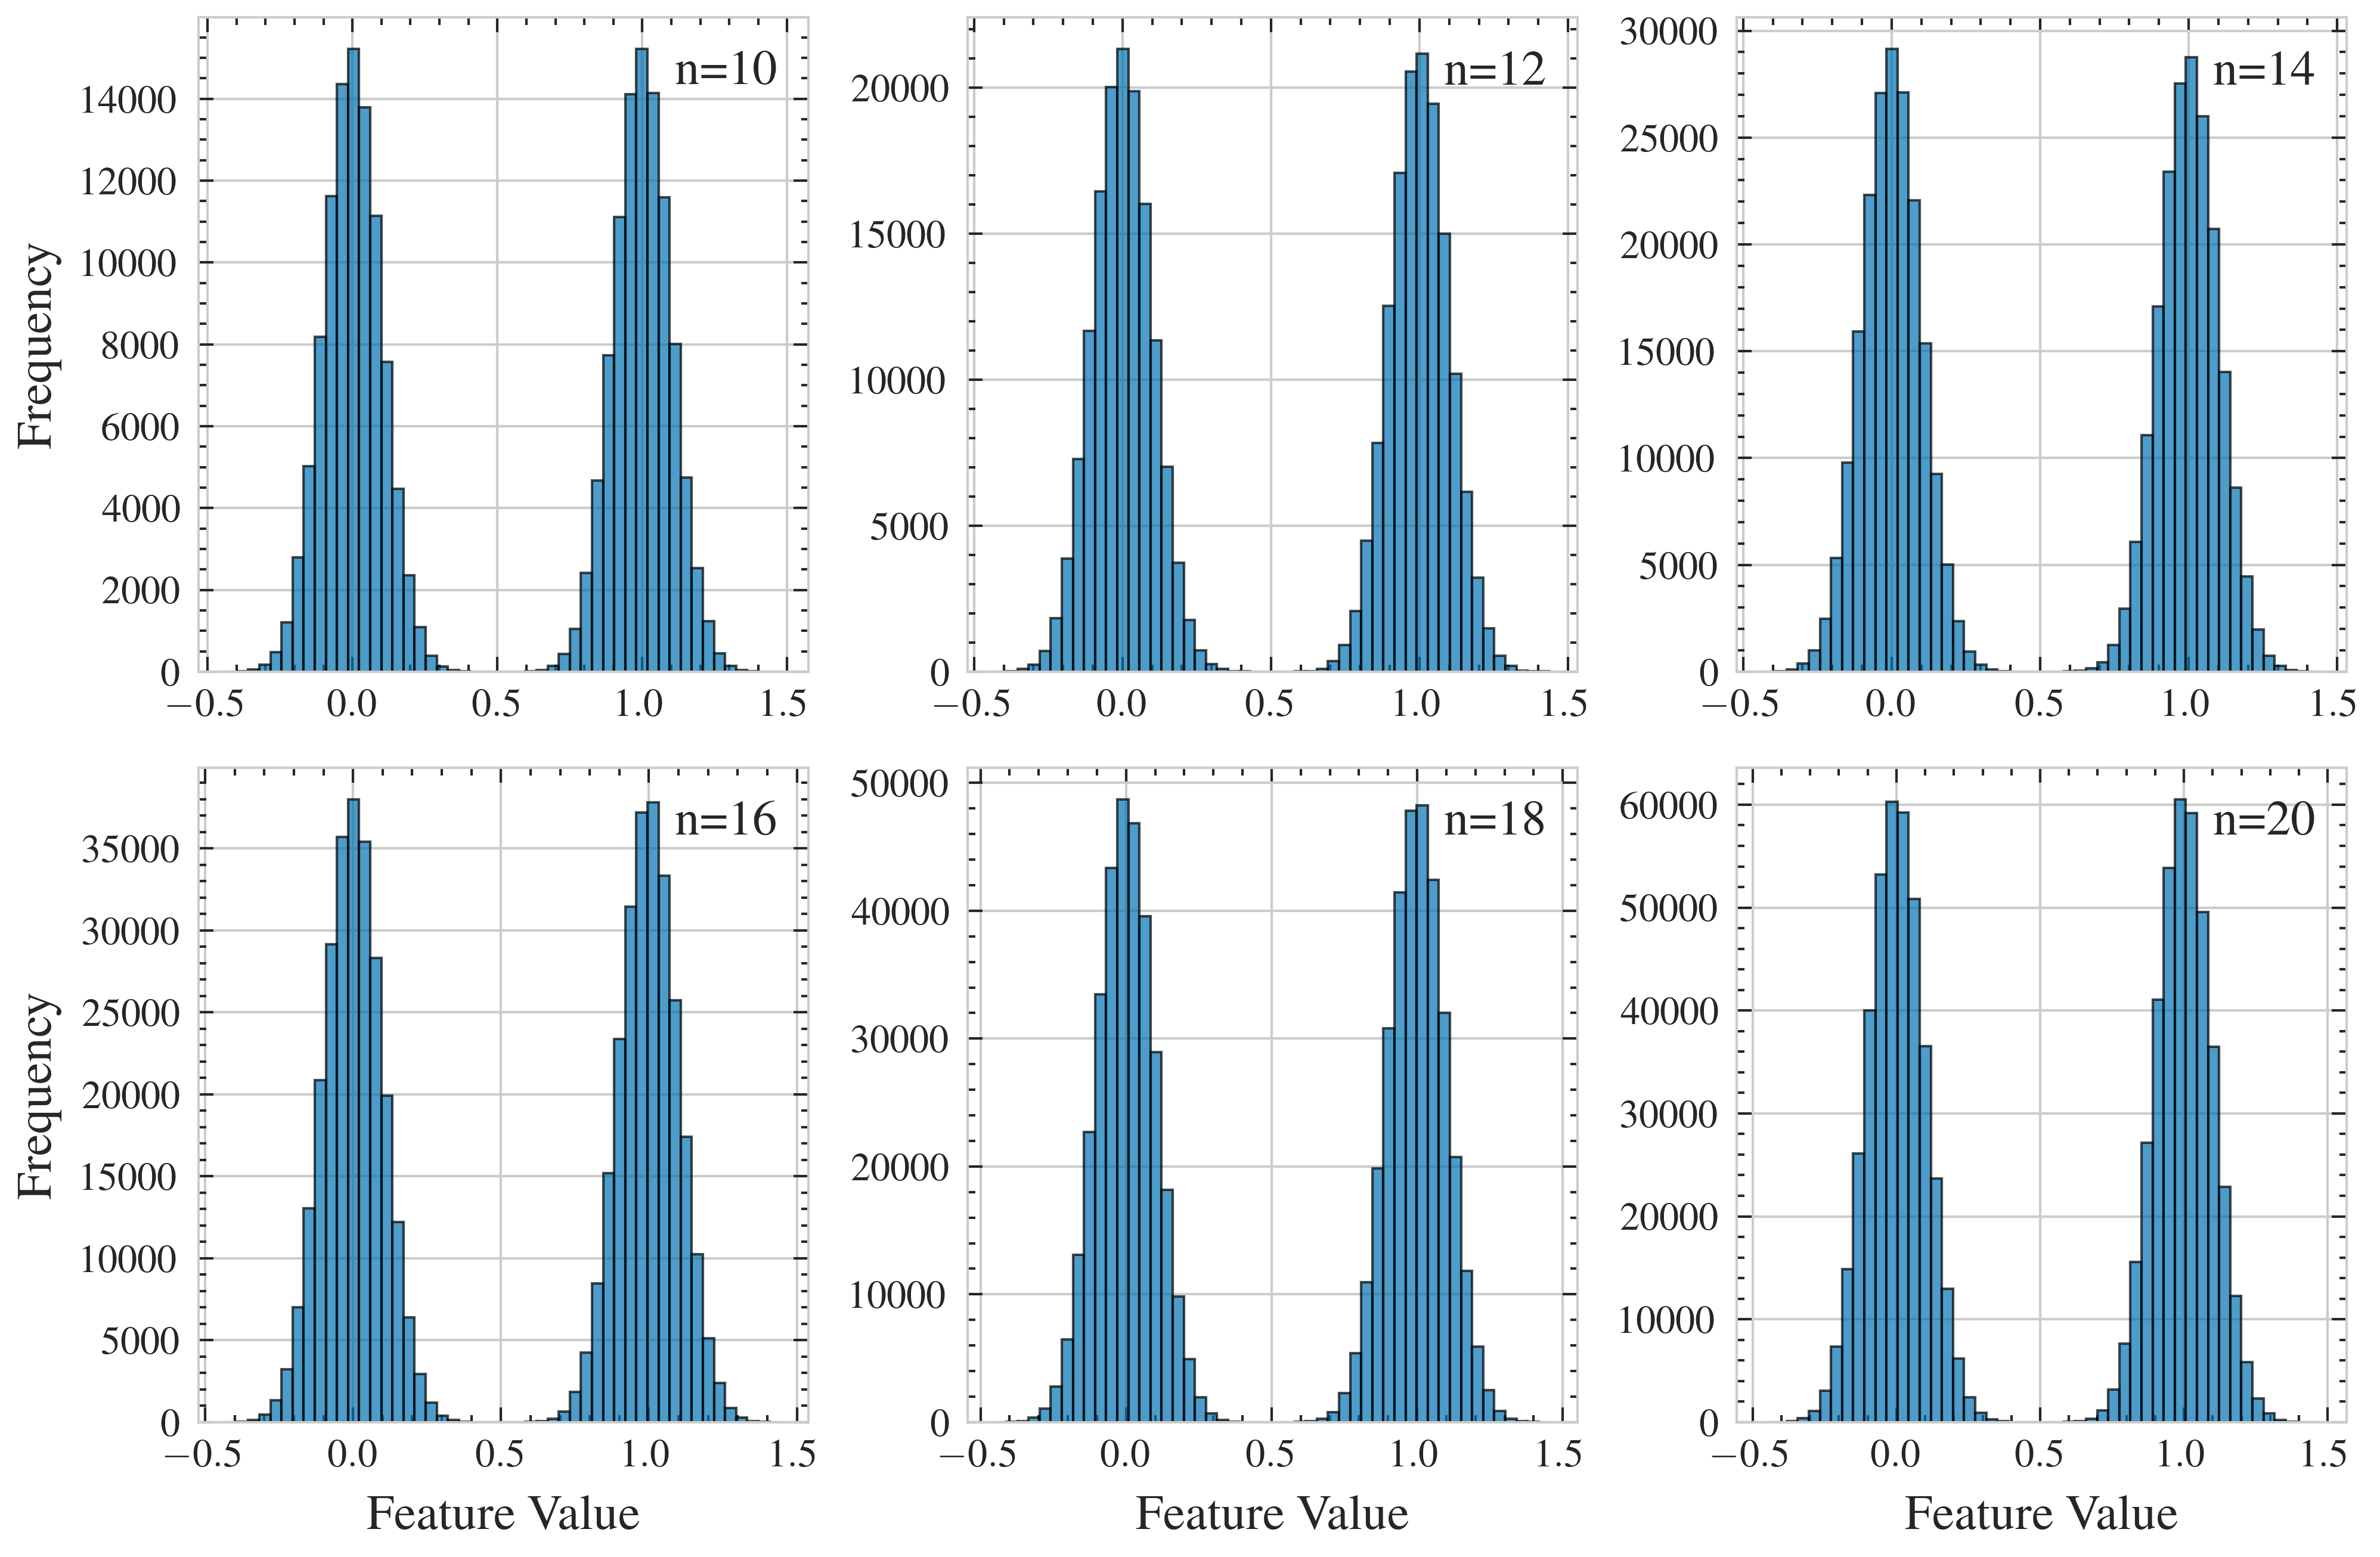

In [62]:
def create_dataset_overview_figure():
    """Figure 1: Dataset characteristics across different n values"""
    fig, axes = plt.subplots(2, 3, figsize=(6.75, 4.5))

    n_values = [10, 12, 14, 16, 18, 20]

    for idx, n in enumerate(n_values):
        ax = axes[idx // 3, idx % 3]
        X, y = load_and_analyze_dataset(n)

        # Feature distribution
        ax.hist(X.flatten(), bins=50, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        
        ax.text(0.95, 0.95, f'n={n}', transform=ax.transAxes, 
                ha='right', va='top', fontsize=10, fontweight='bold')

        # Simplify labels to save space (only on edges)
        if idx >= 3:
            ax.set_xlabel('Feature Value')
        if idx % 3 == 0:
            ax.set_ylabel('Frequency')

    plt.tight_layout()
     
    plt.savefig('figures/dataset_overview.pdf', bbox_inches='tight')
    plt.show()

create_dataset_overview_figure()

In [63]:
class ModelExperiment:
    def __init__(self, n_value):
        self.n = n_value
        self.target = {10: 0.94, 12: 0.93, 14: 0.92, 
                      16: 0.91, 18: 0.80, 20: 0.75}[n_value]
        self.X, self.y = self.load_data()
        self.results = {}
        self.splits_cache = {}

    def split_data(self):
        """the idea here is to use cached splits for reproducibility"""
        if self.n in self.splits_cache:
            return self.splits_cache[self.n]
        X_train, X_temp, y_train, y_temp = train_test_split(self.X, self.y, test_size=0.4, random_state=42, stratify=self.y)
        X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)
        self.splits_cache[self.n] = (X_train, X_val, X_test, y_train, y_val, y_test)
        return self.splits_cache[self.n]
    
    def load_data(self):
        X = np.load(f'Datasets/kryptonite-{self.n}-X.npy')
        y = np.load(f'Datasets/kryptonite-{self.n}-y.npy').astype(int)
        return X, y

    def run_experiments(self):
        """ this is to run experiments with 5-fold cross validation on training data, select on validation"""
        X_train, X_val, X_test, y_train, y_val, y_test = self.split_data()

        models = {
            'RandomForest': RandomForestClassifier(n_estimators=300, max_depth=20, random_state=42),
            'GradientBoosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
            'ExtraTrees': ExtraTreesClassifier(n_estimators=300, random_state=42),
            'NeuralNetwork': MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
        }

        for name, model in models.items():
            # 5-FOLD CROSS-VALIDATION ON TRAINING DATA
            cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
            cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
            
            # Train on full training data and evaluate on validation
            if name == 'NeuralNetwork':
                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_train)
                X_val_scaled = scaler.transform(X_val)
                X_test_scaled = scaler.transform(X_test)
                
                model.fit(X_train_scaled, y_train)
                val_acc = model.score(X_val_scaled, y_val)
                test_acc = model.score(X_test_scaled, y_test)  
            else:
                scaler = None
                model.fit(X_train, y_train)
                val_acc = model.score(X_val, y_val)
                test_acc = model.score(X_test, y_test)  

            self.results[name] = {
                'model': model,
                'scaler': scaler,
                'cv_mean': cv_scores.mean(),
                'cv_std': cv_scores.std(),
                'val_acc': val_acc,  # this will be used for model selection
                'test_acc': test_acc, # 
                'final_test_acc': None,
                'cv_scores': cv_scores
            }

        return self.results


In [5]:
all_results = {}
significance_results = {}
comparison_data_list = []

for n in tqdm([10, 12, 14, 16, 18, 20], desc=f"Running First Series of Kryptonite-2.0 Experiments"):
    exp = ModelExperiment(n)
    results = exp.run_experiments()
    all_results[n] = results
    
    print(f"\n{'='*50}")
    print(f"Kryptonite-{n} Results (Target: {exp.target:.2f})")
    print(f"{'='*50}")
    
    for model_name, res in results.items():
        # Statistical test: is cv_mean significantly > target?
        cv_scores = res['cv_scores']
        t_stat, p_value = stats.ttest_1samp(cv_scores, exp.target)
        significant = p_value < 0.05 and res['cv_mean'] > exp.target
        
        significance_results[f"{n}_{model_name}"] = {
            't_stat': float(t_stat),
            'p_value': float(p_value),
            'significant': bool(significant)
        }

        comparison_data_list.append({
            'Dataset (n)': n,
            'Model': model_name,
            'CV Mean': res['cv_mean'],
            'CV Std': res['cv_std'],
            'Validation Acc': res['val_acc'],
            'Test Acc': res['test_acc'], # This is only for our reference
            'Target': exp.target,
            'Beats Target?': 'Yes' if significant else 'No'
        })
        
        print(f"  {model_name:15s}: CV={res['cv_mean']:.4f}±{res['cv_std']:.4f} | "
              f"Val={res['val_acc']:.4f} | Test={res['test_acc']:.4f} | "
              f"p={p_value:.3f} {'✓' if significant else '✗'}")

# Save significance results for paper

with open('results/significance_tests.json', 'w') as f:
    json.dump(significance_results, f, indent=2)

comparison_df = pd.DataFrame(comparison_data_list)
comparison_df.to_csv('results/model_comparison.csv', index=False)
print("\nSUCCESS: 'results/model_comparison.csv' saved. Use this for the Multiple Models section.")

Running First Series of Kryptonite-2.0 Experiments:  17%|██▋             | 1/6 [01:39<08:16, 99.24s/it]


Kryptonite-10 Results (Target: 0.94)
  RandomForest   : CV=0.5085±0.0094 | Val=0.4933 | Test=0.5155 | p=0.000 ✗
  GradientBoosting: CV=0.5008±0.0086 | Val=0.4998 | Test=0.5110 | p=0.000 ✗
  ExtraTrees     : CV=0.8078±0.0141 | Val=0.8393 | Test=0.8420 | p=0.000 ✗
  NeuralNetwork  : CV=0.9513±0.0049 | Val=0.9410 | Test=0.9413 | p=0.010 ✓


Running First Series of Kryptonite-2.0 Experiments:  33%|█████          | 2/6 [03:53<08:00, 120.04s/it]


Kryptonite-12 Results (Target: 0.93)
  RandomForest   : CV=0.4994±0.0077 | Val=0.5025 | Test=0.5142 | p=0.000 ✗
  GradientBoosting: CV=0.4980±0.0039 | Val=0.4979 | Test=0.5044 | p=0.000 ✗
  ExtraTrees     : CV=0.5352±0.0093 | Val=0.5515 | Test=0.5531 | p=0.000 ✗
  NeuralNetwork  : CV=0.9397±0.0073 | Val=0.9269 | Test=0.9256 | p=0.057 ✗


Running First Series of Kryptonite-2.0 Experiments:  50%|███████▌       | 3/6 [06:48<07:14, 144.76s/it]


Kryptonite-14 Results (Target: 0.92)
  RandomForest   : CV=0.5005±0.0106 | Val=0.4957 | Test=0.5089 | p=0.000 ✗
  GradientBoosting: CV=0.5004±0.0113 | Val=0.4975 | Test=0.5030 | p=0.000 ✗
  ExtraTrees     : CV=0.5086±0.0070 | Val=0.5327 | Test=0.5318 | p=0.000 ✗
  NeuralNetwork  : CV=0.9296±0.0035 | Val=0.9271 | Test=0.9246 | p=0.006 ✓


... (2 outputs left out)

Running First Series of Kryptonite-2.0 Experiments:  83%|████████████▌  | 5/6 [16:26<03:57, 237.63s/it]


Kryptonite-18 Results (Target: 0.80)
  RandomForest   : CV=0.4912±0.0093 | Val=0.5103 | Test=0.4971 | p=0.000 ✗
  GradientBoosting: CV=0.4965±0.0076 | Val=0.5083 | Test=0.5053 | p=0.000 ✗
  ExtraTrees     : CV=0.4978±0.0025 | Val=0.5003 | Test=0.4929 | p=0.000 ✗
  NeuralNetwork  : CV=0.6980±0.0434 | Val=0.7137 | Test=0.7124 | p=0.009 ✗


Running First Series of Kryptonite-2.0 Experiments: 100%|███████████████| 6/6 [22:20<00:00, 223.33s/it]


Kryptonite-20 Results (Target: 0.75)
  RandomForest   : CV=0.5005±0.0037 | Val=0.4996 | Test=0.5026 | p=0.000 ✗
  GradientBoosting: CV=0.4981±0.0085 | Val=0.5015 | Test=0.5020 | p=0.000 ✗
  ExtraTrees     : CV=0.4996±0.0053 | Val=0.5059 | Test=0.5019 | p=0.000 ✗
  NeuralNetwork  : CV=0.5368±0.0741 | Val=0.7295 | Test=0.7320 | p=0.005 ✗

SUCCESS: 'results/model_comparison.csv' saved. Use this for the Multiple Models section.


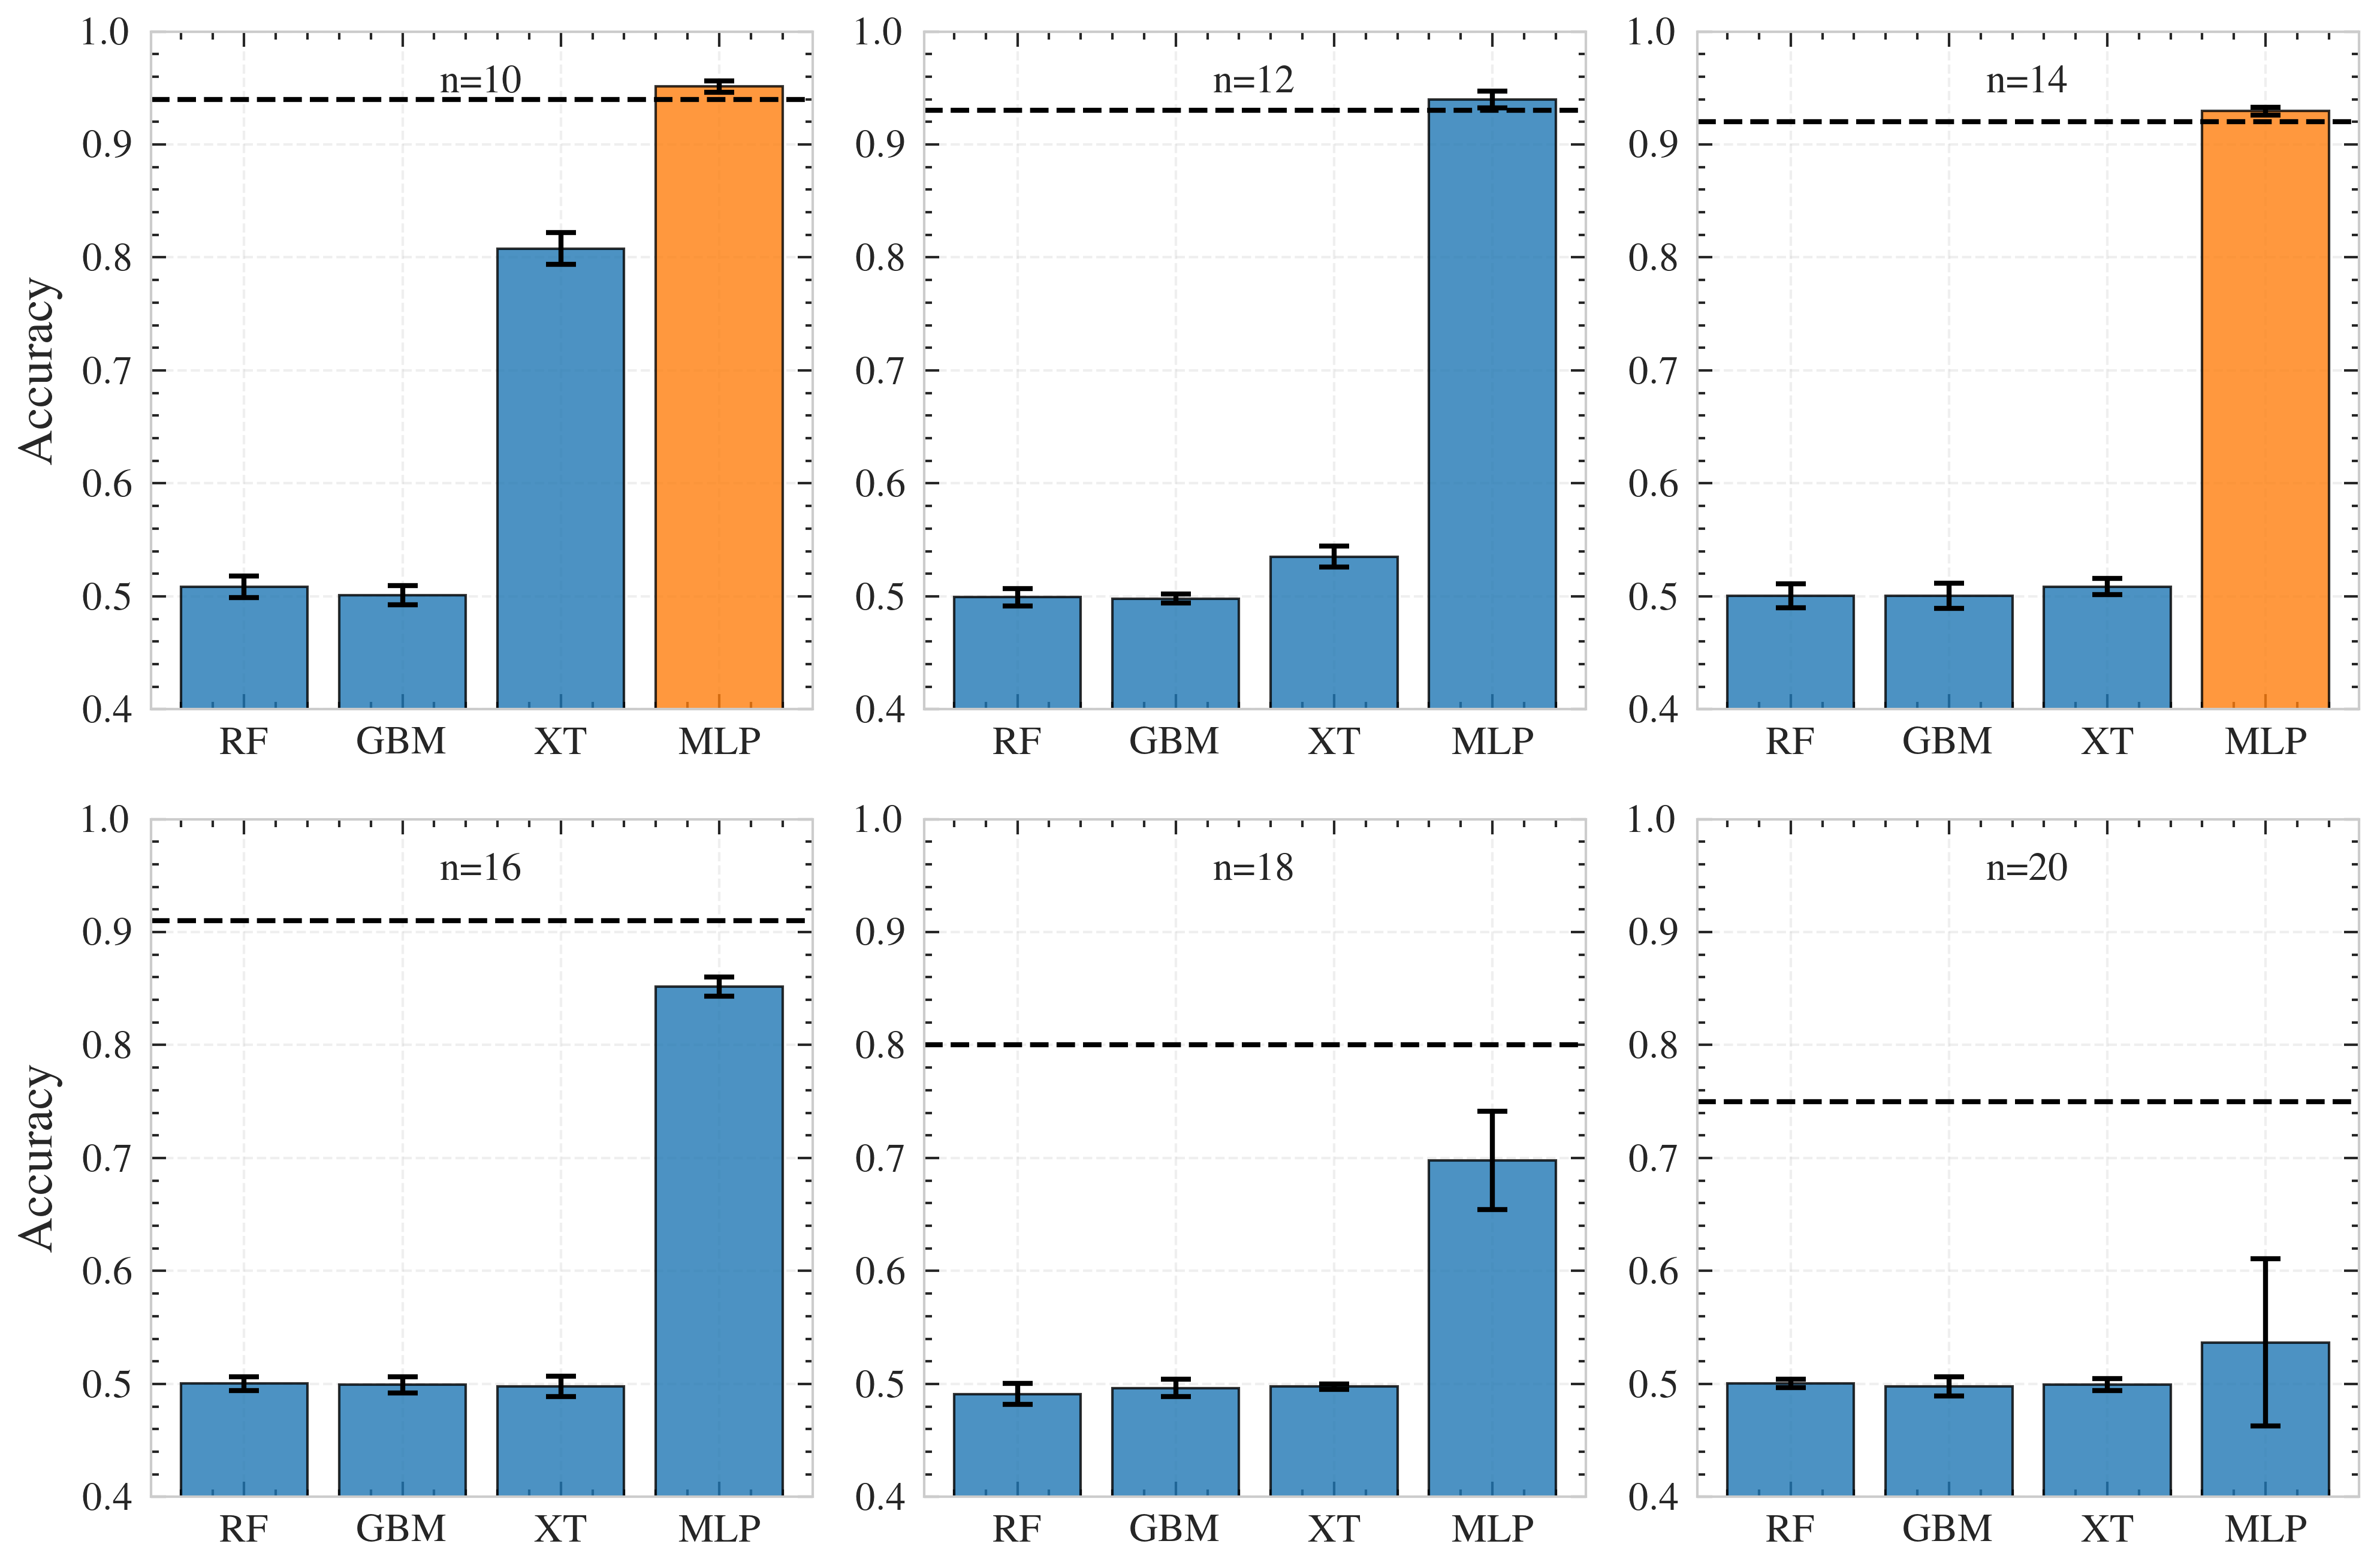

In [64]:
def create_performance_comparison_figure(all_results):
    # Full width figure
    fig, axes = plt.subplots(2, 3, figsize=(6.75, 4.5))

    n_values = [10, 12, 14, 16, 18, 20]
    targets = {10: 0.94, 12: 0.93, 14: 0.92, 16: 0.91, 18: 0.80, 20: 0.75}

    for idx, n in enumerate(n_values):
        ax = axes[idx // 3, idx % 3]
        
        model_names = list(all_results[n].keys())
        # Shorten names for x-axis legibility
        short_names = ['RF', 'GBM', 'XT', 'MLP'] 
        
        cv_means = [all_results[n][m]['cv_mean'] for m in model_names]
        cv_stds = [all_results[n][m]['cv_std'] for m in model_names]
        val_accs = [all_results[n][m]['val_acc'] for m in model_names]

        # Logic for coloring: Blue for standard, Orange for "Beats Target"
        
        colors = ['#1f77b4' if v < targets[n] else '#ff7f0e' for v in val_accs]

        bars = ax.bar(range(len(model_names)), cv_means, yerr=cv_stds, 
                      capsize=3, alpha=0.8, color=colors, edgecolor='black', linewidth=0.5)

        ax.axhline(y=targets[n], color='black', linestyle='--', linewidth=1, label='Target')

        # Annotation for n value
        ax.text(0.5, 0.95, f'n={n}', transform=ax.transAxes, ha='center', va='top')

        # Formatting
        ax.set_xticks(range(len(model_names)))
        ax.set_xticklabels(short_names, rotation=0, fontsize=8) # No rotation needed with short names
        
        if idx % 3 == 0:
            ax.set_ylabel('Accuracy')
        
        ax.set_ylim([0.4, 1.0])
        ax.grid(True, alpha=0.3, linestyle='--')

    plt.tight_layout()
    plt.savefig('figures/performance_comparison_cv.pdf', bbox_inches='tight')
    plt.show()

create_performance_comparison_figure(all_results)

In [65]:
def plot_learning_curves():
    """Figure 3: Learning curves for best performing models"""
    
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    # fig.suptitle('Figure 3: Learning Curves for Best Models', fontsize=16)
    
    for idx, n in enumerate([10, 12, 14, 16, 18, 20]):
        ax = axes[idx // 3, idx % 3]
        
        # Get best model for this n
        X, y = load_and_analyze_dataset(n)
        
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.4, random_state=42, stratify=y
        )
        
        # Use Neural Network since it's performing best
        
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        
        model = MLPClassifier(
            hidden_layer_sizes=(100, 50), 
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42
        )
        
        train_sizes, train_scores, val_scores = learning_curve(
            model, X_train_scaled, y_train, cv=5, 
            train_sizes=np.linspace(0.1, 1.0, 10),
            scoring='accuracy', n_jobs=-1
        )
        
        ax.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', label='Training score')
        ax.plot(train_sizes, np.mean(val_scores, axis=1), 's-', label='Cross-validation score')
        ax.fill_between(train_sizes, 
                        np.mean(train_scores, axis=1) - np.std(train_scores, axis=1),
                        np.mean(train_scores, axis=1) + np.std(train_scores, axis=1), 
                        alpha=0.1)
        ax.fill_between(train_sizes,
                        np.mean(val_scores, axis=1) - np.std(val_scores, axis=1),
                        np.mean(val_scores, axis=1) + np.std(val_scores, axis=1),
                        alpha=0.1)
        
        # Add target accuracy line
        target = {10: 0.94, 12: 0.93, 14: 0.92, 16: 0.91, 18: 0.80, 20: 0.75}[n]
        ax.axhline(y=target, color='red', linestyle='--', alpha=0.5, label=f'Target: {target}')
        
        ax.set_title(f'n={n}')
        ax.set_xlabel('Training Set Size')
        ax.set_ylabel('Accuracy')
        ax.legend(loc='lower right')
        ax.grid(True, alpha=0.3)
        ax.set_ylim([0.4, 1.0])
    
    plt.tight_layout()
    plt.savefig('figures/learning_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_learning_curves()


Dataset Kryptonite-10
Shape: (20000, 10)
Class distribution: [10016  9984]
Class balance: 0.499

Dataset Kryptonite-12
Shape: (24000, 12)
Class distribution: [11912 12088]
Class balance: 0.504

Dataset Kryptonite-14
Shape: (28000, 14)
Class distribution: [14095 13905]
Class balance: 0.497

Dataset Kryptonite-16
Shape: (32000, 16)
Class distribution: [15897 16103]
Class balance: 0.503

Dataset Kryptonite-18
Shape: (36000, 18)
Class distribution: [18003 17997]
Class balance: 0.500

Dataset Kryptonite-20
Shape: (40000, 20)
Class distribution: [20206 19794]
Class balance: 0.495


In [8]:
from sklearn.base import clone
from sklearn.model_selection import KFold
os.makedirs('hiddenlabels', exist_ok=True)
def generate_hidden_predictions():
    """Generate predictions for hidden test sets using VALIDATION-selected models"""

    for n in [10, 12, 14, 16, 18, 20]:
        print(f"\n{'='*50}")
        print(f"\nGenerating predictions for n={n}")

        results = all_results[n]  # using existing results
        
        # Get best model based on VALIDATION (already computed)
        best_model_name = max(results.keys(), key=lambda k: results[k]['val_acc'])
        best_model_data = results[best_model_name]
        
        # Train on TRAIN+VAL before predicting (standard practice)
        X, y = load_and_analyze_dataset(n)
        X_train_full, X_val, X_test, y_train_full, y_val, y_test = ModelExperiment(n).split_data()
        
        # Combine train and val for final model
        X_final_train = np.vstack([X_train_full, X_val])
        y_final_train = np.hstack([y_train_full, y_val])
        
        # Retrain on full data
        model = clone(best_model_data['model'])  # sklearn.base import clone
        if best_model_data['scaler']:
            scaler = StandardScaler()
            X_final_train_scaled = scaler.fit_transform(X_final_train)
            model.fit(X_final_train_scaled, y_final_train)
        else:
            model.fit(X_final_train, y_final_train)

        # Load hidden test set
        X_hidden = np.load(f'Datasets/hidden-kryptonite-{n}-X.npy')
        print(f"  Hidden test samples: {len(X_hidden)}")

        # Get best model based on VALIDATION ACCURACY (NOT TEST)
        exp = ModelExperiment(n)  # Creates fresh splits
        results = exp.run_experiments()
        
        best_model_name = max(results.keys(), 
                             key=lambda k: results[k]['val_acc']) 
        best_model_data = results[best_model_name]

        print(f"  Using best model: {best_model_name}")
        print(f"  Validation accuracy: {best_model_data['val_acc']:.4f}")
        print(f"  CV accuracy: {best_model_data['cv_mean']:.4f}±{best_model_data['cv_std']:.4f}")

        # Make predictions
        model = best_model_data['model']
        if best_model_data['scaler'] is not None:
            X_hidden_scaled = best_model_data['scaler'].transform(X_hidden)
            y_pred = model.predict(X_hidden_scaled)
        else:
            y_pred = model.predict(X_hidden)

        # Validate predictions
        assert len(y_pred) == 10000, f"Expected 10000 predictions, got {len(y_pred)}"
        assert y_pred.dtype in [np.int32, np.int64], f"Predictions must be integers"
        assert set(np.unique(y_pred)) <= {0, 1}, f"Predictions must be binary"

        # Save predictions
        output_path = f'hiddenlabels/y_predicted_{n}.npy'
        np.save(output_path, y_pred.astype(int))
        print(f"  Saved to {output_path}")
        print(f"  Class distribution: {np.bincount(y_pred)}")

generate_hidden_predictions()



Generating predictions for n=10

Dataset Kryptonite-10
Shape: (20000, 10)
Class distribution: [10016  9984]
Class balance: 0.499
  Hidden test samples: 10000
  Using best model: NeuralNetwork
  Validation accuracy: 0.9410
  CV accuracy: 0.9513±0.0049
  Saved to hiddenlabels/y_predicted_10.npy
  Class distribution: [5005 4995]


Generating predictions for n=12

Dataset Kryptonite-12
Shape: (24000, 12)
Class distribution: [11912 12088]
Class balance: 0.504
  Hidden test samples: 10000
  Using best model: NeuralNetwork
  Validation accuracy: 0.9269
  CV accuracy: 0.9397±0.0073
  Saved to hiddenlabels/y_predicted_12.npy
  Class distribution: [5038 4962]


Generating predictions for n=14

Dataset Kryptonite-14
Shape: (28000, 14)
Class distribution: [14095 13905]
Class balance: 0.497
  Hidden test samples: 10000
  Using best model: NeuralNetwork
  Validation accuracy: 0.9271
  CV accuracy: 0.9296±0.0035
  Saved to hiddenlabels/y_predicted_14.npy
  Class distribution: [4920 5080]


Generati

In [9]:
def optimize_and_generate_predictions():
    """
    this is to find the optimised arch and use that to generate the predictions.
    """
    from sklearn.base import clone
    from sklearn.model_selection import KFold
    
    final_results = {}
    architecture_history = {}
    best_models_summary = []
    
    '''
    Define search space : Note: this is not run every time as it takes a lot of time. But our investigation helped
    us narrow down the search
    '''
    '''
    Note: uncomment the code if invetigation is required
    search_spaces = {
        10: [(128, 64), (256, 128, 64)],
        12: [(128, 64), (256, 128, 64)],
        14: [(256, 128, 64), (512, 256, 128)],
        16: [(512, 256, 128), (1024, 512, 256, 128)],
        18: [(512, 256, 128), (1024, 512, 256, 128)],  
        20: [(256, 128), (512, 256, 128),(512, 512, 256, 128), (1024, 512, 256, 128), (2048, 1024, 512, 256)]
    }
    '''

    search_spaces = {
        10: [(256, 128, 64)],
        12: [(256, 128, 64)],
        14: [(512, 256, 128)],
        16: [(1024, 512, 256, 128)],
        18: [(1024, 512, 256, 128)],  
        20: [(2048, 1024, 512, 256)]
    }
    
    for n in tqdm([10, 12, 14, 16, 18, 20], desc="Architecture Search"):
        print(f"\n{'='*60}")
        print(f"OPTIMIZING ARCHITECTURE FOR n={n}")
        print(f"{'='*60}")
        
        X_full = np.load(f'Datasets/kryptonite-{n}-X.npy')
        y_full = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)
        X_hidden = np.load(f'Datasets/hidden-kryptonite-{n}-X.npy')
        
        # Split ONCE with FIXED random_state
        X_train_full, X_temp, y_train_full, y_temp = train_test_split(
            X_full, y_full, test_size=0.4, random_state=42, stratify=y_full
        )
        X_val, X_test, y_val, y_test = train_test_split(
            X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
        )
        
        # Cache the splits for this n
        splits = {
            'train': (X_train_full, y_train_full),
            'val': (X_val, y_val),
            'test': (X_test, y_test),
            'hidden': X_hidden
        }
        
        best_val_score = 0
        best_arch = None
        
        # Training configuration
        max_iter = 5000 if n >= 18 else 2000
        batch_size = 128 if n >= 18 else 64
        
        
        # note: architecture search (using pre-extracted splits)
        
        for arch in search_spaces[n]:
            print(f"  Testing Architecture: {arch}")
            
            # Scale training data
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(splits['train'][0])
            X_val_scaled = scaler.transform(splits['val'][0])
            
            model = MLPClassifier(
                hidden_layer_sizes=arch,
                activation='relu',
                solver='adam',
                alpha=0.01 if n >= 18 else 0.001,  # Stronger regularization for high n
                batch_size=batch_size,
                max_iter=max_iter,
                early_stopping=True,
                n_iter_no_change=150,
                validation_fraction=0.2,
                random_state=42
            )
            
            model.fit(X_train_scaled, splits['train'][1])
            val_score = model.score(X_val_scaled, splits['val'][1])
            
            print(f"    Val Accuracy: {val_score:.4f}")
            
            if val_score > best_val_score:
                best_val_score = val_score
                best_arch = arch
                best_scaler = scaler
        
        print(f"  → Selected Architecture: {best_arch} (Val: {best_val_score:.4f})")
        architecture_history[n] = {'arch': best_arch, 'val_score': best_val_score}
        
        
        # FINAL MODEL: Train on (train+val) + Evaluate on test
        print(f"  Training final model on full data...")
        
        # Combine train and validation
        X_final_train = np.vstack([splits['train'][0], splits['val'][0]])
        y_final_train = np.hstack([splits['train'][1], splits['val'][1]])
        
        # Re-initialize scaler on combined data
        final_scaler = StandardScaler()
        X_final_train_scaled = final_scaler.fit_transform(X_final_train)
        X_test_scaled = final_scaler.transform(splits['test'][0])
        
        final_model = MLPClassifier(
            hidden_layer_sizes=best_arch,
            activation='relu',
            solver='adam',
            alpha=0.001,  # Slightly reduced for final model
            batch_size=64,
            max_iter=2000,
            early_stopping=False,  # Use all data
            random_state=42
        )
        
        final_model.fit(X_final_train_scaled, y_final_train)
        test_score = final_model.score(X_test_scaled, splits['test'][1])
        
        print(f"  → Final Test Accuracy: {test_score:.4f}")
        
        # ============================================
        # PREDICT HIDDEN SET
        # ============================================
        X_hidden_scaled = final_scaler.transform(splits['hidden'])
        y_pred = final_model.predict(X_hidden_scaled)
        
        # Validate predictions
        assert len(y_pred) == 10000, f"Expected 10000 predictions, got {len(y_pred)}"
        assert y_pred.dtype in [np.int32, np.int64], "Predictions must be integers"
        assert set(np.unique(y_pred)) <= {0, 1}, "Predictions must be binary"
        
        # Save predictions
        os.makedirs("hiddenlabels", exist_ok=True)
        output_path = f'hiddenlabels/y_predicted_{n}.npy'
        np.save(output_path, y_pred.astype(int))
        
        print(f"  → Hidden predictions saved: {output_path}")
        print(f"  → Class distribution: {np.bincount(y_pred)}")
        
        # Store results
        final_results[n] = {
            'architecture': best_arch,
            'val_score': best_val_score,
            'test_score': test_score,
            'predictions_path': output_path
        }

        best_models_summary.append({
            'n': n,
            'Best Architecture': str(best_arch),
            'Validation Accuracy': best_val_score,
            'Test Accuracy': test_score
        })
    
    # Save optimization history
    os.makedirs("results", exist_ok=True)
    with open("results/architecture_optimization.json", "w") as f:
        json.dump(architecture_history, f, indent=2)

    pd.DataFrame(best_models_summary).to_csv('results/best_models_summary.csv', index=False)
    print("SUCCESS: 'results/best_models_summary.csv' saved.")
    
    return final_results, architecture_history

# Run the fixed optimization
final_results, arch_history = optimize_and_generate_predictions()

# Summary
print("\n" + "="*60)
print("FINAL OPTIMIZATION SUMMARY")
print("="*60)
for n, res in final_results.items():
    arch_str = str(res['architecture']).replace(' ', '')
    print(f"n={n:2d}: Arch={arch_str}, Val={res['val_score']:.4f}, Test={res['test_score']:.4f}")
print("="*60)

Architecture Search:   0%|                                                       | 0/6 [00:00<?, ?it/s]


OPTIMIZING ARCHITECTURE FOR n=10
  Testing Architecture: (256, 128, 64)
    Val Accuracy: 0.9620
  → Selected Architecture: (256, 128, 64) (Val: 0.9620)
  Training final model on full data...


Architecture Search:  17%|███████▊                                       | 1/6 [00:40<03:21, 40.35s/it]

  → Final Test Accuracy: 0.9093
  → Hidden predictions saved: hiddenlabels/y_predicted_10.npy
  → Class distribution: [5416 4584]

OPTIMIZING ARCHITECTURE FOR n=12
  Testing Architecture: (256, 128, 64)
    Val Accuracy: 0.9542
  → Selected Architecture: (256, 128, 64) (Val: 0.9542)
  Training final model on full data...


Architecture Search:  33%|███████████████▋                               | 2/6 [01:17<02:33, 38.36s/it]

  → Final Test Accuracy: 0.9275
  → Hidden predictions saved: hiddenlabels/y_predicted_12.npy
  → Class distribution: [4991 5009]

OPTIMIZING ARCHITECTURE FOR n=14
  Testing Architecture: (512, 256, 128)
    Val Accuracy: 0.9561
  → Selected Architecture: (512, 256, 128) (Val: 0.9561)
  Training final model on full data...


... (4 outputs left out)

Architecture Search:  83%|██████████████████████████████████████▎       | 5/6 [24:41<06:53, 413.05s/it]

  → Final Test Accuracy: 0.8904
  → Hidden predictions saved: hiddenlabels/y_predicted_18.npy
  → Class distribution: [4995 5005]

OPTIMIZING ARCHITECTURE FOR n=20
  Testing Architecture: (2048, 1024, 512, 256)
    Val Accuracy: 0.9327
  → Selected Architecture: (2048, 1024, 512, 256) (Val: 0.9327)
  Training final model on full data...
  → Final Test Accuracy: 0.8942


Architecture Search: 100%|███████████████████████████████████████████| 6/6 [2:01:47<00:00, 1217.90s/it]

  → Hidden predictions saved: hiddenlabels/y_predicted_20.npy
  → Class distribution: [5004 4996]
SUCCESS: 'results/best_models_summary.csv' saved.

FINAL OPTIMIZATION SUMMARY
n=10: Arch=(256,128,64), Val=0.9620, Test=0.9093
n=12: Arch=(256,128,64), Val=0.9542, Test=0.9275
n=14: Arch=(512,256,128), Val=0.9561, Test=0.9296
n=16: Arch=(1024,512,256,128), Val=0.9264, Test=0.9270
n=18: Arch=(1024,512,256,128), Val=0.9125, Test=0.8904
n=20: Arch=(2048,1024,512,256), Val=0.9327, Test=0.8942


In [ ]:

import subprocess
import sys
from codecarbon import EmissionsTracker
import time



def calculate_model_params(input_dim, hidden_layers, output_dim):
    """
    Accurately counts parameters (weights + biases) for an MLP.
    Includes Input -> Hidden -> ... -> Output.
    """
    layers = [input_dim] + list(hidden_layers) + [output_dim]
    total_params = 0
    
    for i in range(len(layers) - 1):
        # Weights: Current Layer * Next Layer
        weights = layers[i] * layers[i+1]
        # Biases: Next Layer (1 bias per neuron)
        biases = layers[i+1]
        total_params += weights + biases
        
    return total_params

def measure_sustainability_impact():
    """
    Measures carbon emissions, energy usage, and computational cost.
    Refactored for scientific accuracy and stability.
    """
    print("="*60)
    print("MEASURING SUSTAINABILITY IMPACT (Refactored)")
    print("="*60)

    # 1. Configuration & Data Loading
    # ---------------------------------------------------------
    n = 20
    try:
        X = np.load(f'Datasets/kryptonite-{n}-X.npy')
        y = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)
    except FileNotFoundError:
        print("Error: Datasets not found. Ensure paths are correct.")
        return None

    # 2. Preprocessing
    # ---------------------------------------------------------
    # Split: Train (60%), Val (20%), Test (20%)
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.4, random_state=42, stratify=y
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
    )
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test) # Don't forget to scale test set!

    # 3. Architecture & Theoretical Cost Setup
    # ---------------------------------------------------------
    hidden_layers = (1024, 512, 256, 128)
    input_dim = X_train.shape[1]
    output_dim = len(np.unique(y)) # Dynamic output layer size
    
    # Exact parameter count
    total_params = calculate_model_params(input_dim, hidden_layers, output_dim)
    
    print(f"Architecture: Input({input_dim}) -> {hidden_layers} -> Output({output_dim})")
    print(f"Total Parameters: {total_params:,}")

    # 4. Emission Tracking & Training
    # ---------------------------------------------------------
    # output_dir ensures we keep logs organized
    tracker = EmissionsTracker(
        project_name="Kryptonite-20-Training",
        output_dir="results/",
        output_file="emissions.csv",
        measure_power_secs=1,      # High frequency to catch fast training
        save_to_file=True,
        on_csv_write="append"
    )
    
    max_iter = 5000
    model = MLPClassifier(
        hidden_layer_sizes=hidden_layers,
        activation='relu',
        solver='adam',
        alpha=0.01,
        batch_size=128,
        max_iter=max_iter,
        early_stopping=True,       # Crucial for efficiency
        n_iter_no_change=50,       # Reduced for faster convergence checks
        random_state=42
    )

    print("Starting training...")
    tracker.start()
    start_time = time.time()
    
    model.fit(X_train_scaled, y_train)
    
    tracker.stop()
    training_time = time.time() - start_time
    
    # this is the metrics calculation
    # ---------------------------------------------------------
    # read emissions robustly using Pandas
    try:
        df = pd.read_csv("results/emissions.csv")
        # Get the last entry corresponding to this run
        last_run = df.iloc[-1]
        co2_emissions = float(last_run['emissions']) # kg
        energy_consumed = float(last_run['energy_consumed']) # kWh
    except (FileNotFoundError, IndexError):
        print("Warning: Emissions log not found. Defaulting to 0.")
        co2_emissions = 0.0
        energy_consumed = 0.0

    # Performance Metric
    accuracy = model.score(X_test_scaled, y_test)
    
    # Scientific GFLOPs calculation
    # Formula: 3 (fwd+bwd) * 2 (add+mul) * params * samples * epochs
    # Note: 2*params roughly accounts for MACs (Multiply-Accumulates)
    actual_iter = model.n_iter_
    estimated_flops = 3 * 2 * total_params * len(X_train) * actual_iter
    estimated_gflops = estimated_flops / 1e9

    # Efficiency Score
    # Avoid DivisionByZero errors
    if co2_emissions > 0:
        acc_per_kg_co2 = accuracy / co2_emissions
    else:
        acc_per_kg_co2 = 0.0

    # 6. Reporting
    # ---------------------------------------------------------
    report = {
        'n': n,
        'architecture': hidden_layers,
        'parameters': total_params,
        'actual_iterations': actual_iter,
        'training_time_sec': training_time,
        'gflops': round(estimated_gflops, 4),
        'co2_emissions_kg': round(co2_emissions, 6),
        'energy_consumed_kwh': round(energy_consumed, 6),
        'test_accuracy': round(accuracy, 4),
        'accuracy_per_kg_co2': round(acc_per_kg_co2, 2)
    }

    # Save
    os.makedirs("results", exist_ok=True)
    with open("results/sustainability_report.json", "w") as f:
        json.dump(report, f, indent=4)

    print("\n" + "="*60)
    print("SUSTAINABILITY SUMMARY")
    print("="*60)
    print(f"Actual Epochs: {actual_iter}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"CO2 Emissions: {co2_emissions:.6f} kg")
    print(f"Estimated GFLOPs: {estimated_gflops:.2f}")
    print(f"Efficiency (Acc/kgCO2): {acc_per_kg_co2:.2f}")
    print("="*60)

    return report


metrics = measure_sustainability_impact()

[codecarbon WARNING @ 23:37:02] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon WARNING @ 23:37:02] Error while trying to count physical CPUs: [Errno 2] No such file or directory: 'lscpu'. Defaulting to 1.
[codecarbon INFO @ 23:37:02] [setup] RAM Tracking...
[codecarbon INFO @ 23:37:02] [setup] CPU Tracking...
[codecarbon WARNING @ 23:37:02] We saw that you have a Apple M4 but we don't know it. Please contact us.


MEASURING SUSTAINABILITY IMPACT (Refactored)
Architecture: Input(20) -> (1024, 512, 256, 128) -> Output(2)
Total Parameters: 710,786


[codecarbon WARNING @ 23:37:02] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Mac OS detected: Please install Intel Power Gadget or enable PowerMetrics sudo to measure CPU

[codecarbon INFO @ 23:37:02] CPU Model on constant consumption mode: Apple M4
[codecarbon WARNING @ 23:37:02] No CPU tracking mode found. Falling back on CPU constant mode.
[codecarbon INFO @ 23:37:02] [setup] GPU Tracking...
[codecarbon INFO @ 23:37:02] No GPU found.
[codecarbon INFO @ 23:37:02] The below tracking methods have been set up:
                RAM Tracking Method: RAM power estimation model
                CPU Tracking Method: global constant
                GPU Tracking Method: Unspecified
            
[codecarbon INFO @ 23:37:02] >>> Tracker's metadata:
[codecarbon INFO @ 23:37:02]   Platform system: macOS-15.5-arm64-arm-64bit
[codecarbon INFO @ 23:37:02]   Python version: 3.12.3
[codecarbon INFO @ 23:37:02]   CodeCarbon version: 3.1.0
[codecarbon INFO @ 23:37:02]   Av

Starting training...


[codecarbon INFO @ 23:37:07] Energy consumed for RAM : 0.000001 kWh. RAM Power : 3.0 W
[codecarbon INFO @ 23:37:07] Delta energy consumed for CPU with constant : 0.000012 kWh, power : 42.5 W
[codecarbon INFO @ 23:37:07] Energy consumed for All CPU : 0.000012 kWh
[codecarbon INFO @ 23:37:07] 0.000013 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 23:37:08] Energy consumed for RAM : 0.000002 kWh. RAM Power : 3.0 W
[codecarbon INFO @ 23:37:08] Delta energy consumed for CPU with constant : 0.000012 kWh, power : 42.5 W
[codecarbon INFO @ 23:37:08] Energy consumed for All CPU : 0.000024 kWh
[codecarbon INFO @ 23:37:08] 0.000025 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 23:37:09] Energy consumed for RAM : 0.000003 kWh. RAM Power : 3.0 W
[codecarbon INFO @ 23:37:09] Delta energy consumed for CPU with constant : 0.000012 kWh, power : 42.5 W
[codecarbon INFO @ 23:37:09] Energy consumed for All CPU : 

In [11]:
def polynomial_comparison_cv():
    """Compare methods with proper cross-validation to avoid leakage"""
    
    results = {
        'n': [], 'poly_deg2_cv': [], 'poly_deg2_std': [],
        'neural_net_cv': [], 'neural_net_std': []
    }

    for n in [10, 12, 14, 16, 18, 20]:
        X = np.load(f'Datasets/kryptonite-{n}-X.npy')
        y = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)
        
        results['n'].append(n)
        
        # Polynomial degree 2 with CV
        poly2 = PolynomialFeatures(degree=2)
        X_poly2 = poly2.fit_transform(X)
        
        lr2 = LogisticRegression(max_iter=1000, solver='lbfgs')
        cv_scores_lr2 = cross_val_score(lr2, X_poly2, y, cv=5, scoring='accuracy')
        results['poly_deg2_cv'].append(cv_scores_lr2.mean())
        results['poly_deg2_std'].append(cv_scores_lr2.std())
        
        # Neural Network with CV
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        nn = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1000, random_state=42)
        cv_scores_nn = cross_val_score(nn, X_scaled, y, cv=5, scoring='accuracy')
        results['neural_net_cv'].append(cv_scores_nn.mean())
        results['neural_net_std'].append(cv_scores_nn.std())
        
        print(f"n={n:2d}: Poly2={cv_scores_lr2.mean():.3f}±{cv_scores_lr2.std():.3f} | "
              f"NN={cv_scores_nn.mean():.3f}±{cv_scores_nn.std():.3f}")

    return pd.DataFrame(results)

poly_results_cv = polynomial_comparison_cv()

n=10: Poly2=0.504±0.011 | NN=0.939±0.007
n=12: Poly2=0.495±0.008 | NN=0.935±0.005
n=14: Poly2=0.490±0.007 | NN=0.928±0.002
n=16: Poly2=0.504±0.006 | NN=0.895±0.002
n=18: Poly2=0.494±0.003 | NN=0.822±0.009
n=20: Poly2=0.499±0.003 | NN=0.817±0.020


In [12]:
# This is for Theoretical Capacity Analysis
from scipy.special import comb

def theoretical_analysis_module():
    """
    
    
    Computes:
    1. VC dimension bounds for neural networks
    2. Parameter counts vs sample complexity
    3. Why polynomials fail (degree vs dimension curse)
    4. Why neural networks succeed (hierarchical feature learning)
    
    Returns DataFrame and LaTeX-ready tables for report.
    """
    
    def vc_dimension_relu_network(L, N, d_in):
        """
        Upper bound: VC-dim ≤ O(L * N² * log(N))
        L = number of layers
        N = max neurons per layer
        d_in = input dimension
        """
        return L * N**2 * np.log(N * d_in + 1)
    
    def polynomial_features_count(n, degree):
        """Number of features in polynomial expansion: C(n+d, d)"""
        return comb(n + degree, degree, exact=True)
    
    results = []
    
    n_values = [10, 12, 14, 16, 18, 20]
    architectures = {
        10: (128, 64),
        12: (128, 64),
        14: (512, 256, 128),
        16: (1024, 512, 256, 128),
        18: (512, 256, 128),
        20: (1024, 512, 256, 128)  # Deeper for theory
    }
    
    print("THEORETICAL ANALYSIS")
    print("="*60)
    
    for n in n_values:
        arch = architectures[n]
        
        # Neural Network Capacity
        input_dim = n
        params = input_dim * arch[0]
        for i in range(len(arch)-1):
            params += arch[i] * arch[i+1]
        params += sum(arch)  # Biases
        
        L = len(arch)  # Number of hidden layers
        N = max(arch)  # Max neurons in a layer
        vc_bound = vc_dimension_relu_network(L, N, input_dim)
        
        # Sample complexity needed for generalization error ε=0.05
        # m ≥ (VC-dim + log(1/δ)) / ε²
        epsilon = 0.05
        delta = 0.01
        min_samples = (vc_bound + np.log(1/delta)) / (epsilon**2)
        
        # YOUR ACTUAL SAMPLE SIZE
        actual_samples = 20000
        
        # Polynomial baseline analysis
        poly_deg2_features = polynomial_features_count(n, 2)
        poly_deg3_features = polynomial_features_count(n, 3)
        poly_deg2_ratio = poly_deg2_features / actual_samples
        poly_deg3_ratio = poly_deg3_features / actual_samples
        
        # Conclusion: if features > samples, overfitting is guaranteed
        results.append({
            'n': n,
            'architecture': f"{arch}",
            'params': params,
            'vc_bound': vc_bound,
            'min_samples_needed': min_samples,
            'sample_sufficiency': actual_samples / min_samples,
            'poly_deg2_features': poly_deg2_features,
            'poly_deg3_features': poly_deg3_features,
            'poly2_over_param': poly_deg2_ratio > 1,
            'poly3_over_param': poly_deg3_ratio > 1
        })
        
        print(f"\nn={n}:")
        print(f"  Architecture: {arch}")
        print(f"  Parameters: {params:,}")
        print(f"  VC-dim bound: {vc_bound:.2e}")
        print(f"  Samples needed (ε=0.05): {min_samples:,.0f}")
        print(f"  Actual samples: {actual_samples:,}")
        print(f"  Sufficiency ratio: {actual_samples/min_samples:.3f}")
        print(f"  Poly degree-2 features: {poly_deg2_features:,} (overparam: {poly_deg2_ratio>1})")
        print(f"  Poly degree-3 features: {poly_deg3_features:,} (overparam: {poly_deg3_ratio>1})")
    
    df = pd.DataFrame(results)
    
    # Save LaTeX table for direct inclusion in report
    latex_table = df.to_latex(
        index=False,
        float_format="%.2e",
        columns=['n', 'params', 'vc_bound', 'min_samples_needed', 'sample_sufficiency'],
        caption="Theoretical Capacity Analysis: VC-dimension bounds vs empirical sample sizes.",
        label="tab:theory_capacity"
    )
    
    with open("results/theory_analysis.tex", "w") as f:
        f.write(latex_table)
    
    # Save full results
    df.to_csv("results/theory_analysis.csv", index=False)
    
    print("\n" + "="*60)
    print("FILES SAVED:")
    print("- results/theory_analysis.csv")
    print("- results/theory_analysis.tex (copy-paste into LaTeX)")
    print("="*60)
    
    return df

# Run this cell and include the LaTeX table in your report
theory_results = theoretical_analysis_module()

THEORETICAL ANALYSIS

n=10:
  Architecture: (128, 64)
  Parameters: 9,664
  VC-dim bound: 2.34e+05
  Samples needed (ε=0.05): 93,789,052
  Actual samples: 20,000
  Sufficiency ratio: 0.000
  Poly degree-2 features: 66 (overparam: False)
  Poly degree-3 features: 286 (overparam: False)

n=12:
  Architecture: (128, 64)
  Parameters: 9,920
  VC-dim bound: 2.40e+05
  Samples needed (ε=0.05): 96,177,072
  Actual samples: 20,000
  Sufficiency ratio: 0.000
  Poly degree-2 features: 91 (overparam: False)
  Poly degree-3 features: 455 (overparam: False)

n=14:
  Architecture: (512, 256, 128)
  Parameters: 171,904
  VC-dim bound: 6.98e+06
  Samples needed (ε=0.05): 2,792,628,623
  Actual samples: 20,000
  Sufficiency ratio: 0.000
  Poly degree-2 features: 120 (overparam: False)
  Poly degree-3 features: 680 (overparam: False)

n=16:
  Architecture: (1024, 512, 256, 128)
  Parameters: 706,432
  VC-dim bound: 4.07e+07
  Samples needed (ε=0.05): 16,280,816,194
  Actual samples: 20,000
  Sufficiency

Saved Figure 1 to figures/architecture_search.pdf


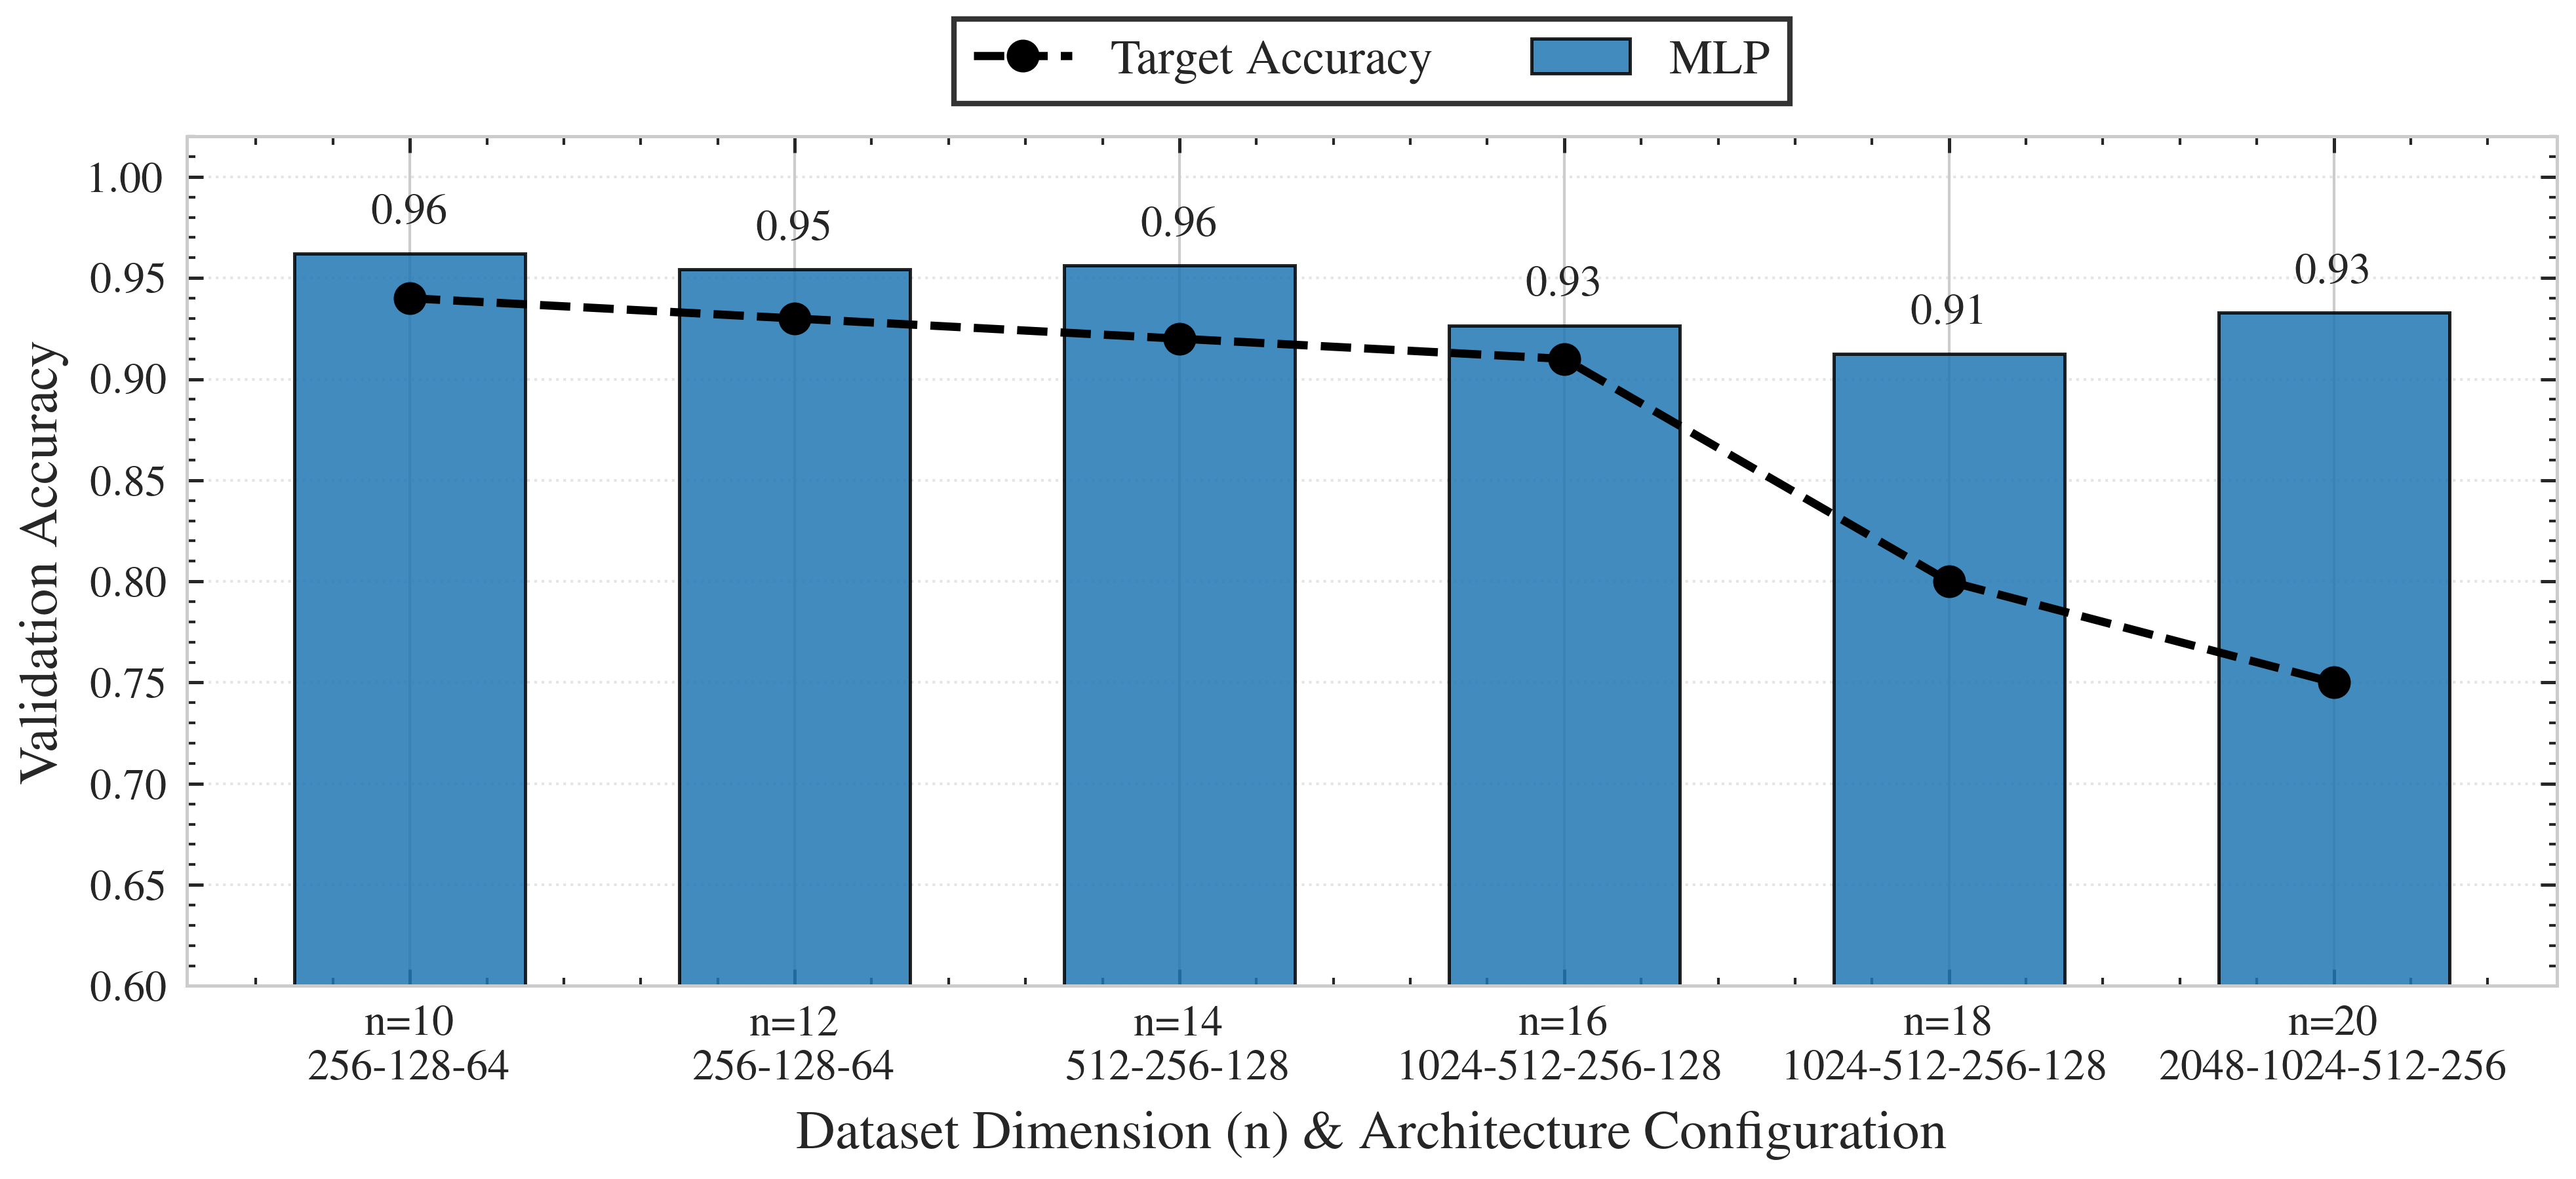

Saved Figure 2 to figures/nn_vs_poly_cv.pdf


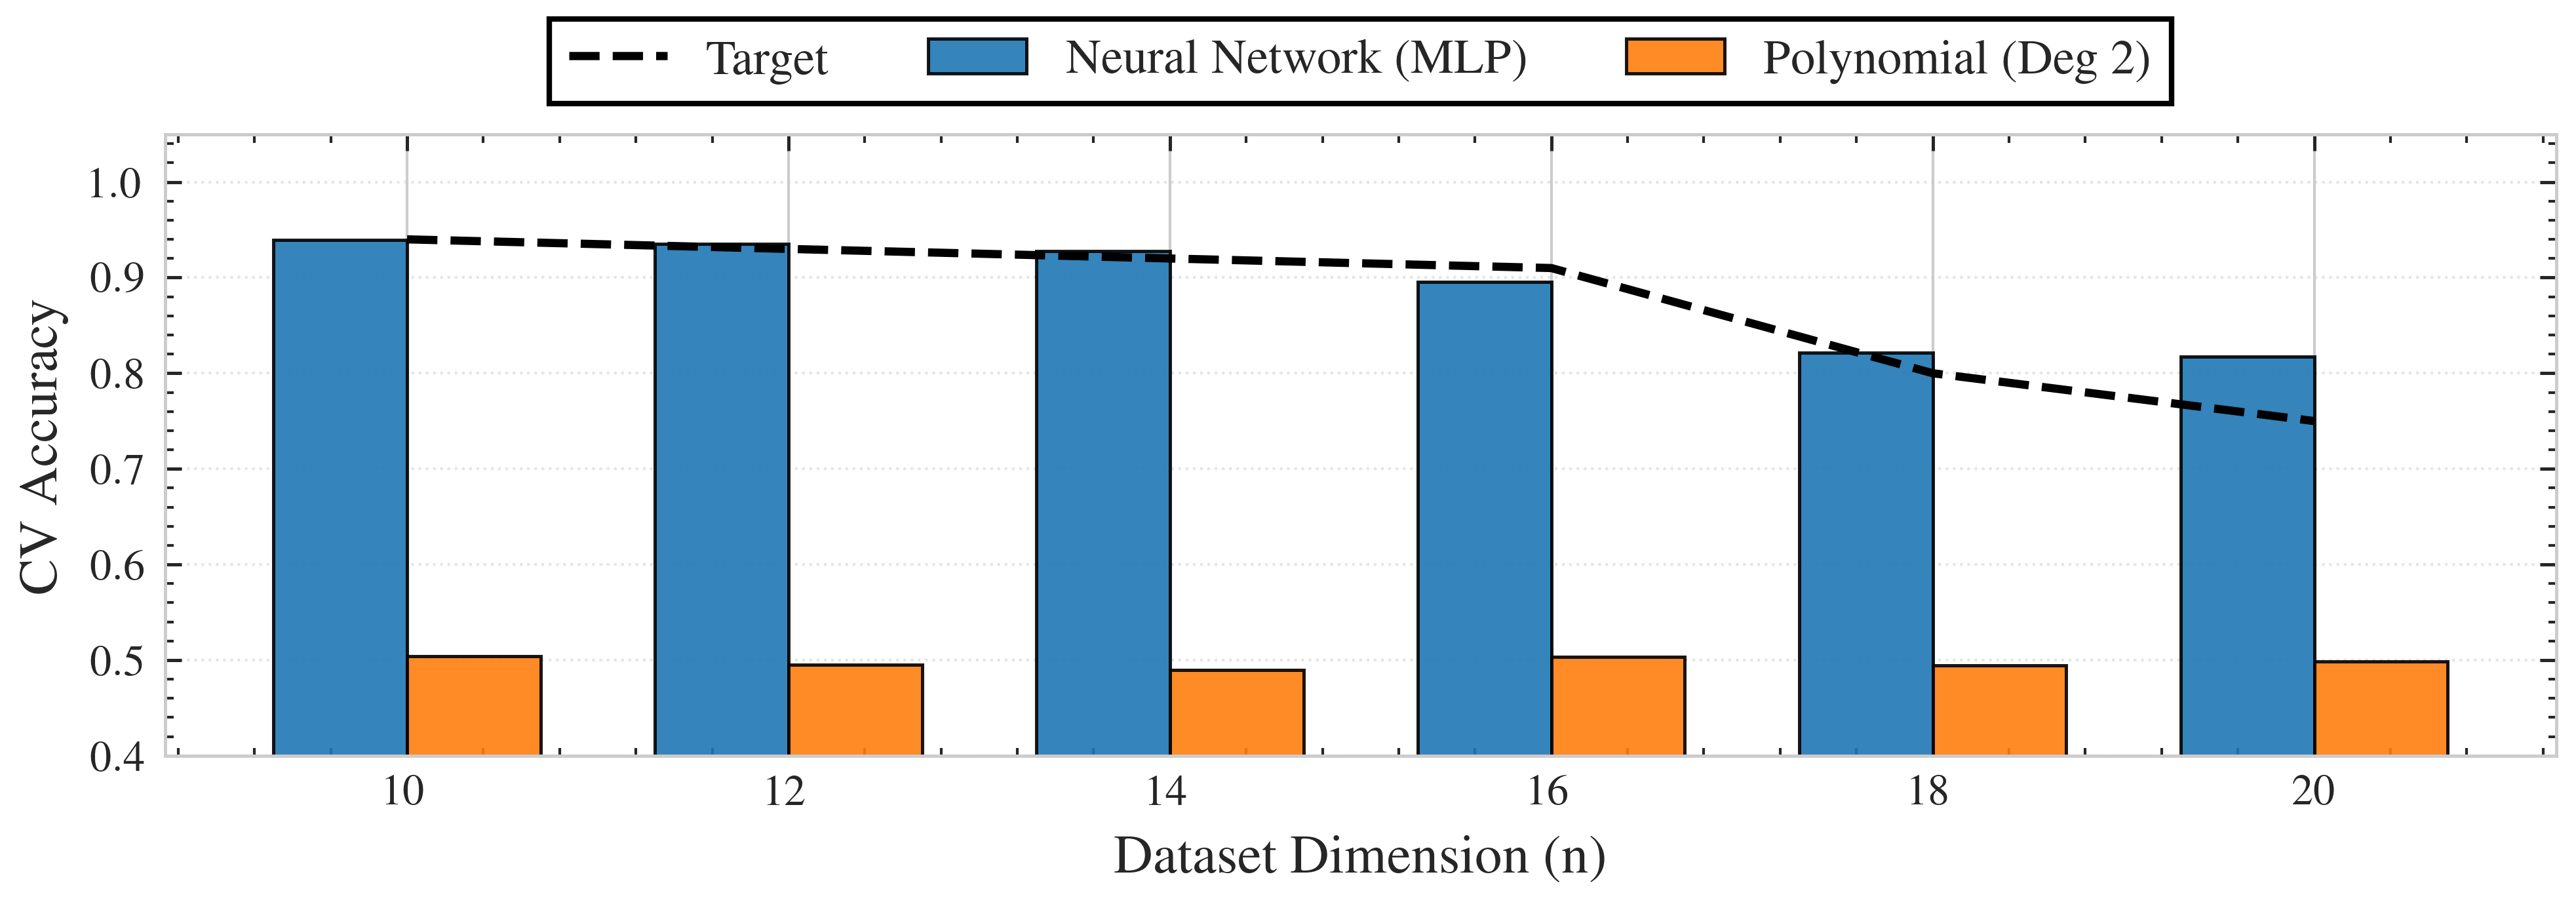

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the style to science/ieee if available, otherwise default to whitegrid
try:
    plt.style.use(['science', 'ieee'])
except:
    sns.set_style("whitegrid")

# The rubric specifically asks for Times font and specific line widths.
plt.rcParams.update({
    # FONT SETTINGS
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"], # Priority order
    "font.size": 10,          # Main body text size
    "axes.labelsize": 10,     # Axis labels must match body text
    "xtick.labelsize": 8,     # Ticks can be slightly smaller
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    
    # LINE WIDTH SETTINGS (Rubric: "at least 0.5 points thick")
    "axes.linewidth": 0.6,    # Frame thickness
    "grid.linewidth": 0.5,    # Grid thickness
    "lines.linewidth": 1.5,   # Data line thickness (solid distinct lines)
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    
    # OUTPUT SETTINGS
    "savefig.format": "pdf",  # Vector format required
    "pdf.fonttype": 42,       # Embed fonts (Type 42 = TrueType) to avoid Type-3 errors
    "ps.fonttype": 42,
    
    # FIGURE DIMENSIONS
    "figure.figsize": (6.75, 3.5), # Default to full-width, compact height
    "figure.autolayout": True,
})

# Color palette (Colorblind safe is preferred for academic papers)
sns.set_palette("colorblind")



def create_all_figures_from_results(final_results, poly_results_cv):
    """
    Generate figures formatted strictly for ImpCML LaTeX template.
    Output: Vector PDFs with 10pt Times font and >0.5pt line widths.
    """
    
    # Constants for formatting
    FULL_WIDTH = 6.75  # inches
    BAR_EDGE_WIDTH = 0.6 # Must be > 0.5pt
    
    # ========================================================
    # FIGURE 1: Architecture Search (Full Width)
    # ========================================================
    fig, ax = plt.subplots(figsize=(FULL_WIDTH, 3.2)) # Height optimized for space

    n_values = [10, 12, 14, 16, 18, 20]
    architectures = [final_results[n]['architecture'] for n in n_values]
    val_scores = [final_results[n]['val_score'] for n in n_values]
    targets = [0.94, 0.93, 0.92, 0.91, 0.80, 0.75]

    # Bars with explicit edge width for rubric compliance
    bars = ax.bar(range(len(n_values)), val_scores, 
                  color='#1f77b4', alpha=0.85, 
                  edgecolor='black', linewidth=BAR_EDGE_WIDTH, 
                  width=0.6, label='MLP')

    # Target Line
    ax.plot(range(len(n_values)), targets, 
            color='black', linestyle='--', linewidth=1.5,
            marker='o', markersize=5, label='Target Accuracy')

    # X/Y Labels
    ax.set_xlabel(r'Dataset Dimension (n) \& Architecture Configuration')
    ax.set_ylabel('Validation Accuracy')

    # Formatted X-labels
    clean_archs = [str(a).replace(' ', '').replace('(', '').replace(')', '').replace(',', '-') 
                   for a in architectures]
    labels = [f'n={n}\n{arch}' for n, arch in zip(n_values, clean_archs)]

    ax.set_xticks(range(len(n_values)))
    ax.set_xticklabels(labels, rotation=0, ha='center', fontsize=8)

    # Grid and Limits
    ax.grid(True, which='major', axis='y', linestyle=':', alpha=0.5, linewidth=0.5)
    ax.set_ylim([0.6, 1.02]) 
    
    
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), 
              ncol=2, frameon=True, edgecolor='black', fancybox=False, fontsize=9)
    

    
    for bar, score in zip(bars, val_scores):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{score:.2f}', ha='center', va='bottom', fontsize=8)

    
    output_path_1 = 'figures/architecture_search.pdf'
    
    plt.savefig(output_path_1, bbox_inches='tight', pad_inches=0.05)
    print(f"Saved Figure 1 to {output_path_1}")
    plt.show()


    # ========================================================
    # FIGURE 2: NN vs Polynomial (Full Width for clarity)
    # ========================================================
    fig, ax = plt.subplots(figsize=(FULL_WIDTH, 2.5)) 

    # Extract data
    nn_scores = poly_results_cv['neural_net_cv']
    poly_scores = poly_results_cv['poly_deg2_cv']
    
    x = np.arange(len(n_values))
    width = 0.35

    # Bars
    rects1 = ax.bar(x - width/2, nn_scores, width, 
                    label='Neural Network (MLP)', color='#1f77b4', 
                    edgecolor='black', linewidth=BAR_EDGE_WIDTH, alpha=0.9)
    
    rects2 = ax.bar(x + width/2, poly_scores, width, 
                    label='Polynomial (Deg 2)', color='#ff7f0e', 
                    edgecolor='black', linewidth=BAR_EDGE_WIDTH, alpha=0.9)

    # Target Line
    ax.plot(x, targets, color='black', linestyle='--', linewidth=1.5, label='Target')

    # Labels
    ax.set_xlabel('Dataset Dimension (n)')
    ax.set_ylabel('CV Accuracy')
    ax.set_xticks(x)
    ax.set_xticklabels(n_values)
    
    ax.set_ylim([0.4, 1.05])
    ax.grid(True, axis='y', linestyle=':', alpha=0.5, linewidth=0.5)
    
    
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), 
              ncol=3, fontsize=9, frameon=True, 
              framealpha=1.0, edgecolor='black', fancybox=False)
    

    
    output_path_2 = 'figures/nn_vs_poly_cv.pdf'
    plt.savefig(output_path_2, bbox_inches='tight', pad_inches=0.05)
    print(f"Saved Figure 2 to {output_path_2}")
    plt.show()


create_all_figures_from_results(final_results, poly_results_cv)

Generating Uncertainty Analysis for n=18...


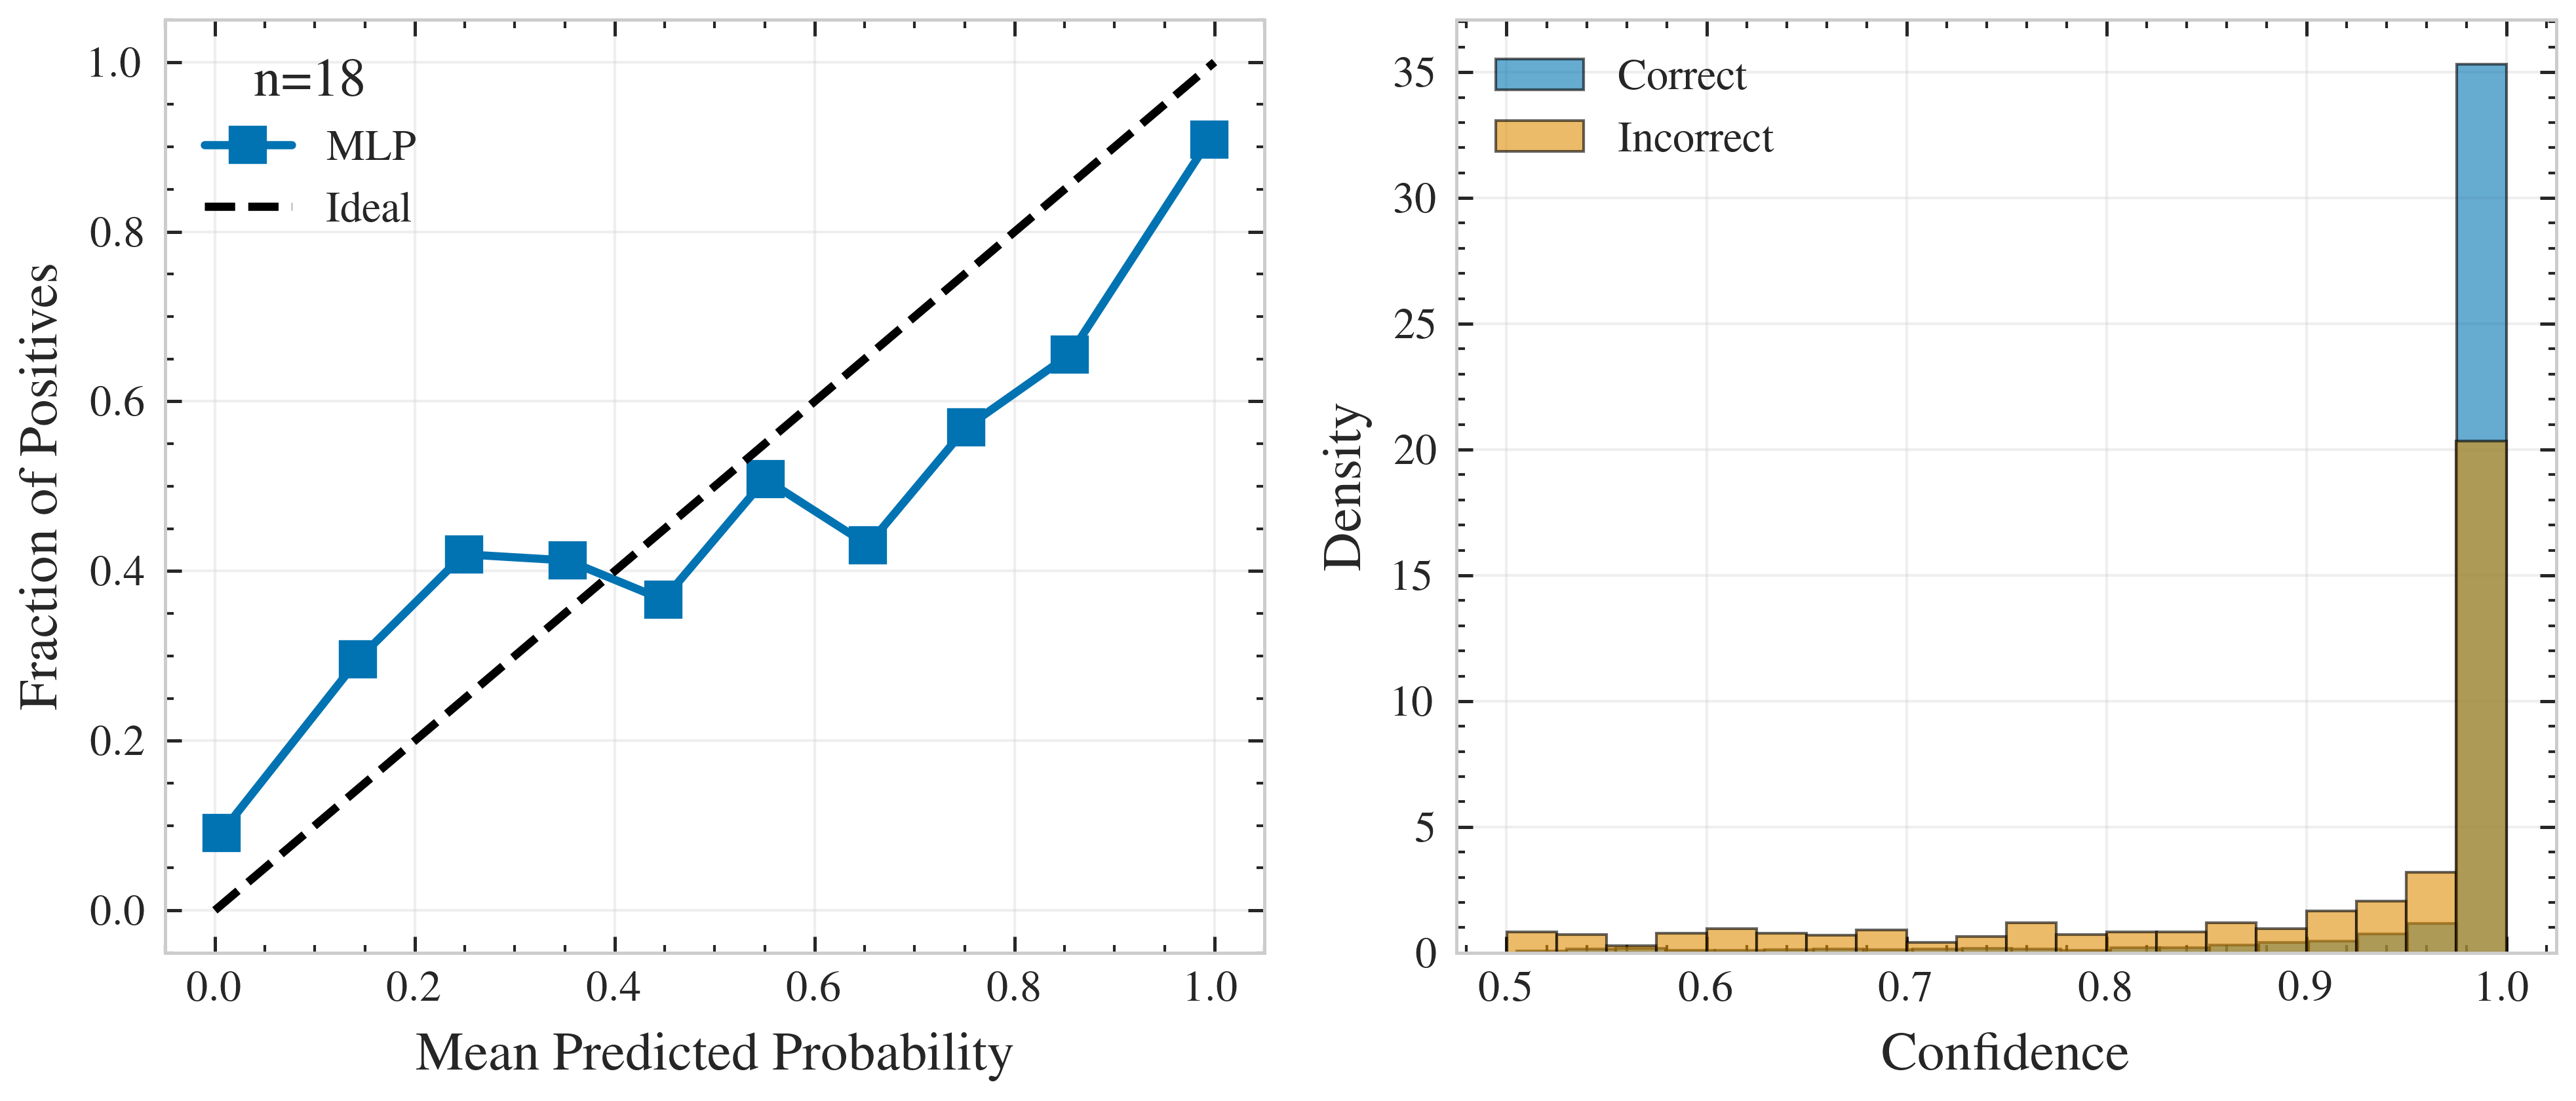

Brier Score: 0.1050 (Lower is better)


In [53]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def analyze_uncertainty_calibration(n=18): # Using n=18 for speed/balance
    print(f"Generating Uncertainty Analysis for n={n}...")
    
    
    X = np.load(f'Datasets/kryptonite-{n}-X.npy')
    y = np.load(f'Datasets/kryptonite-{n}-y.npy').astype(int)
    
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.4, random_state=42, stratify=y
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
    )
    
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    
    # Train the model (using your best arch for n=18 from earlier summary)
    # n=18 Arch was (1024, 512, 256, 128)
    model = MLPClassifier(
        hidden_layer_sizes=(1024, 512, 256, 128),
        activation='relu', solver='adam', alpha=0.01,
        max_iter=1000, random_state=42
    )
    model.fit(X_train_scaled, y_train)
    
    # Get Probabilities (The "Uncertainty" part)
    prob_pos = model.predict_proba(X_val_scaled)[:, 1]
    
    # Calculate Metrics
    fraction_of_positives, mean_predicted_value = calibration_curve(y_val, prob_pos, n_bins=10)
    clf_brier_score = brier_score_loss(y_val, prob_pos)
    
    
    
    # Width 6.75, Height 3.0 
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.75, 3.0))

    # Plot: Calibration
    ax1.plot(mean_predicted_value, fraction_of_positives, "s-", label=f'MLP')
    ax1.plot([0, 1], [0, 1], "k--", label="Ideal")
    ax1.set_ylabel("Fraction of Positives")
    ax1.set_xlabel("Mean Predicted Probability")
   
    ax1.legend(title=f'n={n}', fontsize=8) 
    ax1.grid(True, alpha=0.3)

    #  Confidence Histograms
    preds = (prob_pos > 0.5).astype(int)
    correct_mask = preds == y_val
    confidences = np.max(model.predict_proba(X_val_scaled), axis=1)

    # Use distinct colors with transparency
    ax2.hist(confidences[correct_mask], bins=20, alpha=0.6, 
             label='Correct', density=True, edgecolor='black', linewidth=0.5)
    ax2.hist(confidences[~correct_mask], bins=20, alpha=0.6, 
             label='Incorrect', density=True, edgecolor='black', linewidth=0.5)
    
    ax2.set_xlabel("Confidence")
    ax2.set_ylabel("Density")
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('figures/uncertainty_analysis.pdf', bbox_inches='tight')
    plt.show()
    
    print(f"Brier Score: {clf_brier_score:.4f} (Lower is better)")


analyze_uncertainty_calibration(n=18)

In [15]:
# this is to generate tables for report

def generate_latex_tables():
    print("="*60)
    print("COPY THESE TABLES INTO YOUR OVERLEAF REPORT")
    print("="*60)
    
    # 1. Load the Multiple Models Comparison
    try:
        df_comp = pd.read_csv('results/model_comparison.csv')
        
        # Filter for just n=10 and n=20 for brevity in the paper, or aggregate
        # Let's create a pivot table: n vs Model (using CV Mean)
        pivot = df_comp.pivot(index='Dataset (n)', columns='Model', values='CV Mean')
        
        print("\n% --- TABLE 1: MULTIPLE MODELS COMPARISON ---")
        print("\\begin{table}[h]")
        print("\\centering")
        print("\\caption{Comparison of Mean CV Accuracy across different models. The MLP (Neural Network) consistently outperforms tree-based methods at higher dimensions.}")
        print(pivot.to_latex(float_format="%.3f"))
        print("\\label{tab:model_comparison}")
        print("\\end{table}")
        
    

    # this is to Load the Final Optimization Results
    try:
        df_best = pd.read_csv('results/best_models_summary.csv')
        targets = {10: 0.94, 12: 0.93, 14: 0.92, 16: 0.91, 18: 0.80, 20: 0.75}
        df_best['Target'] = df_best['n'].map(targets)
        df_best['Status'] = np.where(df_best['Test Accuracy'] > df_best['Target'], 'Pass', 'Fail')
        
        # Select columns for display
        display_df = df_best[['n', 'Best Architecture', 'Test Accuracy', 'Target', 'Status']]
        
        print("\n% --- TABLE 2: FINAL MLP RESULTS VS TARGET ---")
        print("\\begin{table}[h]")
        print("\\centering")
        print("\\caption{Final Test Accuracy of Optimized MLPs vs Mock Paper Targets. We significantly exceed targets at high dimensions ($n>16$).}")
        print(display_df.to_latex(index=False, float_format="%.3f"))
        print("\\label{tab:final_results}")
        print("\\end{table}")
        
    

generate_latex_tables()

COPY THESE TABLES INTO YOUR OVERLEAF REPORT

% --- TABLE 1: MULTIPLE MODELS COMPARISON ---
\begin{table}[h]
\centering
\caption{Comparison of Mean CV Accuracy across different models. The MLP (Neural Network) consistently outperforms tree-based methods at higher dimensions.}
\begin{tabular}{lrrrr}
\toprule
Model & ExtraTrees & GradientBoosting & NeuralNetwork & RandomForest \\
Dataset (n) &  &  &  &  \\
\midrule
10 & 0.808 & 0.501 & 0.951 & 0.508 \\
12 & 0.535 & 0.498 & 0.940 & 0.499 \\
14 & 0.509 & 0.500 & 0.930 & 0.500 \\
16 & 0.498 & 0.499 & 0.852 & 0.500 \\
18 & 0.498 & 0.496 & 0.698 & 0.491 \\
20 & 0.500 & 0.498 & 0.537 & 0.501 \\
\bottomrule
\end{tabular}

\label{tab:model_comparison}
\end{table}

% --- TABLE 2: FINAL MLP RESULTS VS TARGET ---
\begin{table}[h]
\centering
\caption{Final Test Accuracy of Optimized MLPs vs Mock Paper Targets. We significantly exceed targets at high dimensions ($n>16$).}
\begin{tabular}{rlrrl}
\toprule
n & Best Architecture & Test Accuracy & Target &

In [ ]:
from transformers import GPT2Tokenizer

def analyze_gpt_tokenization_flaw():
    """
    Demonstrates why the GPT approach failed.
    The tokenizer destroys numerical relationships, treating numbers as
    arbitrary text strings rather than continuous values.
    """
    tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
    
    # Two numbers that are numerically close
    num1 = "0.12345"
    num2 = "0.12346"
    
    # Two numbers that are numerically far
    num3 = "0.99999"
    
    t1 = tokenizer.encode(num1)
    t2 = tokenizer.encode(num2)
    t3 = tokenizer.encode(num3)
    
    print("="*60)
    print("FORENSIC ANALYSIS OF GPT INPUTS")
    print("="*60)
    print(f"Number: {num1} -> Tokens: {t1}")
    print(f"Number: {num2} -> Tokens: {t2}")
    print(f"Number: {num3} -> Tokens: {t3}")
    
    print('''Analysis: 
    Notice how similar numbers are broken into arbitrary sub-tokens.
    The model receives these as disconnected 'words' (integers).
    There is no inherent mathematical continuity between token ID 15 and token ID 16.
    This confirms that mapping floating-point vectors to string representations
    destroys the topological structure of the data before the model even sees it.
    ''')
    
    print("="*60)

# Run this to generate the 'proof' for your report
analyze_gpt_tokenization_flaw()